# **Bibliotecas**

In [ ]:
%pip install opencv-python

In [ ]:
# Instalação das dependências do Pipeline de Polarimetria
%pip install "numpy<2" scipy pandas matplotlib astropy photutils astropop

In [ ]:
%pip install --force-reinstall --no-deps matplotlib

In [ ]:
%pip install --force-reinstall matplotlib kiwisolver pillow cycler pyparsing contourpy

In [ ]:
%pip install --force-reinstall pillow

In [1]:
import os
import glob
import warnings
import concurrent.futures
import numpy as np
import matplotlib.pyplot as plt
import glob
import pandas as pd
import shutil
import cv2

In [2]:
from astropy.io import fits
from astropy import units as u
from astropy.utils.exceptions import AstropyWarning
from astropy.stats import sigma_clipped_stats, sigma_clip

In [3]:
from astropop.image import imcombine, processing, imarith
from astropop.framedata import read_framedata
from astropop.file_collection import FitsFileGroup
from astropop.polarimetry import SLSDualBeamPolarimetry

In [4]:
from photutils.detection import DAOStarFinder
from photutils.centroids import centroid_com
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

In [5]:
from collections import defaultdict
from matplotlib.patches import Circle

In [6]:
# Silencia os avisos do HIERARCH
warnings.simplefilter('ignore', category=AstropyWarning)

# **Caminho dos Dados**

In [7]:
#Caminho até chegar chegar antes na pasta da noite
CAMINHO_PASTA__REDUCAO = '/home/likeableng/BeACoN/arquivos_de_reducao/'

In [8]:
#Colocar os dados da noite
DATA = "20180411" #ex: "AAAAMMDD"
NOME_ESTRELA = "nsco" #ex: "paqr" "osco"

# **Ajuste Pré redução**

In [9]:
#Ajuste data
mes = int(DATA[4:6])

nome_mes = ['', 'jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 
            'ago', 'set', 'out', 'nov', 'dez']

data_ajustada = DATA[2:4]+nome_mes[mes]+DATA[6:]

In [10]:
#Caminhos para pastas reduced e raw

raw_dir = f"{CAMINHO_PASTA__REDUCAO}{data_ajustada}/raw/"

reduced_dir = f"{CAMINHO_PASTA__REDUCAO}{data_ajustada}/reduced/"
os.makedirs(reduced_dir, exist_ok=True)

In [11]:
#Caminho para dados estrela
pasta_raw_estrela = f'{raw_dir}{NOME_ESTRELA}'
pasta_reduced_estrela = f'{reduced_dir}{NOME_ESTRELA}'
os.makedirs(pasta_reduced_estrela, exist_ok=True)

#Caminho para dados calib
pasta_raw_calib = f'{raw_dir}calib/'
pasta_reduced_calib = f'{reduced_dir}calib/'
os.makedirs(pasta_reduced_calib, exist_ok=True)

In [ ]:
#Cria a pasta para o filtro e move o ficheiro para a respetiva pasta de filtro

# Percorre todos os ficheiros na pasta da estrela
for nome_ficheiro in os.listdir(pasta_raw_estrela):
    caminho_origem = os.path.join(pasta_raw_estrela, nome_ficheiro)

    if os.path.isfile(caminho_origem) and nome_ficheiro.endswith('.fits'):
        partes = nome_ficheiro.split('_')
        
        # Para nomes como '48lib_F1_001.fits', partes[1] será 'F1'
        if len(partes) >= 3:
            etiqueta_filtro = partes[1] 

            
            pasta_filtro = os.path.join(pasta_raw_estrela, etiqueta_filtro)
            os.makedirs(pasta_filtro, exist_ok=True)

            
            caminho_destino = os.path.join(pasta_filtro, nome_ficheiro)
            shutil.move(caminho_origem, caminho_destino)
            #print(f"Movido: {nome_ficheiro}  ->  {etiqueta_filtro}/")

print("\n✅ Todos os ficheiros foram organizados nas respetivas pastas de filtro!")

In [ ]:
#Função para extrair o número final do arquivo para ordenação correta
for item in os.listdir(pasta_raw_estrela):
    caminho_pasta_filtro = os.path.join(pasta_raw_estrela, item)
    
    # Processa apenas se for um diretório (pasta de filtro)
    if os.path.isdir(caminho_pasta_filtro):
        arquivos_fits = glob.glob(os.path.join(caminho_pasta_filtro, '*.fits'))
        
        if not arquivos_fits:
            continue
            
        
        def extrair_numero(caminho):
            nome = os.path.basename(caminho)
            parte_num = nome.replace('.fits', '').split('_')[-1]
            return int(parte_num) if parte_num.isdigit() else 0

        arquivos_ordenados = sorted(arquivos_fits, key=extrair_numero)

        #print(f"\n--- Renumerando arquivos em {item} ({len(arquivos_ordenados)} imagens) ---")

        # Renomeia mantendo o prefixo e redefinindo a contagem para 001, 002, 003...
        for idx, caminho_antigo in enumerate(arquivos_ordenados, start=1):

            nome_antigo = os.path.basename(caminho_antigo)
            partes = nome_antigo.replace('.fits', '').split('_')
            
            prefixo = "_".join(partes[:-1])
            
            novo_nome = f"{prefixo}_{idx:03d}.fits"
            caminho_novo = os.path.join(caminho_pasta_filtro, novo_nome)
            
            os.rename(caminho_antigo, caminho_novo)
            #print(f"{nome_antigo}  ->  {novo_nome}")


In [ ]:
#Move cada arquivo de dentro da subpasta para a pasta_raw_estrela e apaga as subpastas 
for item in os.listdir(pasta_raw_estrela):
    caminho_subpasta = os.path.join(pasta_raw_estrela, item)
    
    if os.path.isdir(caminho_subpasta):
        print(f"Movendo arquivos da pasta '{item}' de volta...")
        
        for nome_arquivo in os.listdir(caminho_subpasta):
            caminho_origem = os.path.join(caminho_subpasta, nome_arquivo)
            caminho_destino = os.path.join(pasta_raw_estrela, nome_arquivo)
            
            if os.path.isfile(caminho_origem):
                shutil.move(caminho_origem, caminho_destino)
        
        os.rmdir(caminho_subpasta)
       

# **Funções Motoras**

In [ ]:
#Ajustar nome dos arquivos, alterando o filtro de F# para b,v,r,i

mapeamento = {
    'F1': 'b',
    'F2': 'v',
    'F3': 'r',
    'F4': 'i'
}

def ajustar_nome_filtro(caminho_da_pasta):
# Percorre todos os arquivos dentro da pasta especificada
    for nome_arquivo in os.listdir(caminho_da_pasta):
        if nome_arquivo.endswith('.fits'):
            for chave, letra in mapeamento.items():
                marcador_antigo = f'_{chave}_'
                marcador_novo = f'_{letra}_'
            
                if marcador_antigo in nome_arquivo:
                    # É preciso juntar o caminho da pasta com o nome do arquivo
                    caminho_antigo = os.path.join(caminho_da_pasta, nome_arquivo)
                    novo_nome = nome_arquivo.replace(marcador_antigo, marcador_novo)
                    caminho_novo = os.path.join(caminho_da_pasta, novo_nome)
                
                    os.rename(caminho_antigo, caminho_novo)
                    print(f'{nome_arquivo}  ->  {novo_nome}')
                    break


In [ ]:
#Transformar imagens 3D em 2D

def descompactar_cubos_3d(pasta):    
    # Achar arquivos FITS na pasta de entrada
    arquivos_fits = glob.glob(os.path.join(pasta, '*.fits'))
    print(f"Encontrados {len(arquivos_fits)} arquivos na pasta de entrada.\n")
    
    for caminho_arquivo in arquivos_fits:
        nome_base = os.path.basename(caminho_arquivo).replace('.fits', '')

        try:
            # Ignora o ficheiro se estiver vazio (0 bytes) para evitar OSError
            if os.path.getsize(caminho_arquivo) == 0:
                print(f"Ignorando '{nome_base}.fits' (Ficheiro vazio/0 bytes).")
                continue

            dados, header = fits.getdata(caminho_arquivo, header=True)
            
            # Verifica a dimensão da matriz
            if dados.ndim == 3:
                num_imagens = dados.shape[0]
                print(f"Descompactando '{nome_base}.fits' ({num_imagens} fatias)...")
                
                for i in range(num_imagens):
                    fatia_2d = dados[i]
                    
                    # Cria um nome sequencial (ex: bias_001_001.fits)
                    nome_saida = f"{nome_base}_{i+1:03d}.fits"
                    caminho_saida = os.path.join(pasta, nome_saida)
                    
                    # Salva a fatia 2D com o cabeçalho original.
                    fits.writeto(caminho_saida, fatia_2d, header, overwrite=True)
                    
            elif dados.ndim == 2:
                print(f"Ignorando '{nome_base}.fits' (Já é 2D).")
            else:
                print(f"Ignorando '{nome_base}.fits' (Formato não suportado).")
                
        except OSError as e:
            # Captura especificamente ficheiros corrompidos ou não suportados pelo astropy
            print(f"Erro ao ler '{nome_base}.fits': Ficheiro corrompido ou inválido. A ignorar...")
        except Exception as e:
            # Previne que outros erros parem o loop
            print(f"Erro inesperado no ficheiro '{nome_base}.fits': {e}")
            
    print("\nDescompactação concluída!")


In [ ]:
#Fazer o Master BIAS - sem usar a extração de raios cósmicos

def criar_master_bias(pasta_entrada, pasta_saida):
    print("\n[Calibração] Criando Master Bias por PREAMP (otimizado para velocidade)...")
    fg = FitsFileGroup(location=pasta_entrada, fits_ext=['.fits'], ext=0)
    
    bias_files = fg.filtered({'OBJECT': 'bias'}).files
    
    arquivos_por_preamp = defaultdict(list)
    for arq in bias_files:
        hdr = fits.getheader(arq)
        if hdr.get('NAXIS') == 2:
            # Pega o valor original (ex: '5.1x' ou '1x')
            preamp_raw = str(hdr.get('PREAMP', 'UNKNOWN'))
            
            # Limpa o texto: tira o 'x' e corta tudo depois do ponto
            preamp_val = preamp_raw.lower().replace('x', '').split('.')[0]
            
            arquivos_por_preamp[preamp_val].append(arq)
            
    for preamp_val, arq_2d in arquivos_por_preamp.items():
        print(f"-> Processando Bias para PREAMP: {preamp_val} ({len(arq_2d)} arquivos)")
        
        frames = [read_framedata(f, unit='adu', use_memmap_backend=True) for f in arq_2d]
        gain = float(frames[0].header['GAIN']) * u.electron/u.adu
        
        for frame in frames:
            processing.gain_correct(frame, gain, inplace=True)
            # Sem L.A. Cosmic para processamento rápido
            
        master = imcombine(frames, method='median')
        master.meta['astropop master_type'] = 'bias'
        master.meta['PREAMP'] = preamp_val
        
        sufixo_preamp = f"_g{preamp_val}" if preamp_val != '1' else ""
        caminho_out = os.path.join(pasta_saida, f'master_bias{sufixo_preamp}.fits')
        
        master.write(caminho_out, overwrite=True, no_fits_standard_units=True)
        print(f"   Salvo: {caminho_out}\n")


In [ ]:
#Fazer o Mater Flat - sem usar a extração de raios cósmicos

letra_filtro = ["", "b", "v", "r", "i"]

def criar_master_flat(pasta_in, pasta_out):
    main_fg = FitsFileGroup(location=pasta_in, fits_ext=['.fits'], ext=0)
    flat_files = main_fg.filtered({'OBJECT': 'flat'}).files

    # 1. Agrupamento manual duplo (por Filtro e Preamp limpo)
    arquivos_por_grupo = defaultdict(list)
    for arq in flat_files:
        hdr = fits.getheader(arq)
        if hdr.get('NAXIS') == 2:
            # Extrai e limpa o PREAMP (ex: '5.1x' vira '5')
            preamp_raw = str(hdr.get('PREAMP', 'UNKNOWN'))
            preamp_val = preamp_raw.lower().replace('x', '').split('.')[0]
            
            # Extrai o filtro
            filtro_val = str(hdr.get('FILTER', 'UNKNOWN'))
            
            # Agrupa os dois juntos
            arquivos_por_grupo[(filtro_val, preamp_val)].append(arq)

    # 2. Processa cada grupo separadamente
    for (filtro_val, preamp_val), arquivos_flat_2d in arquivos_por_grupo.items():
        print(f"\n--- Processando Master Flat | Filtro: {filtro_val} | PREAMP: {preamp_val} ({len(arquivos_flat_2d)} arquivos) ---")
        
        # Define sufixo e carrega o Bias correto
        sufixo_preamp = f"_g{preamp_val}" if preamp_val != '1' else ""
        caminho_master_bias = os.path.join(pasta_out, f'master_bias{sufixo_preamp}.fits')
        
        if not os.path.exists(caminho_master_bias):
            print(f"ERRO: {caminho_master_bias} não encontrado! Abortando este flat.")
            continue
            
        master_bias = read_framedata(caminho_master_bias)

        flat_frames = [read_framedata(f, unit='adu', use_memmap_backend=True) for f in arquivos_flat_2d]
        gain = float(flat_frames[0].header['GAIN']) * u.electron / u.adu

        for f_idx, frame in enumerate(flat_frames):
            print(f" -> Processando flat [{filtro_val}] {f_idx+1}/{len(flat_frames)}", end='\r')
            processing.gain_correct(frame, gain, inplace=True)
            processing.subtract_bias(frame, master_bias, inplace=True)

        print(f"\nCombinando e normalizando Master Flat ({filtro_val}, PREAMP {preamp_val})...")
        master_flat = imcombine(flat_frames, method='median')
        mean_value = master_flat.mean()
        master_flat = imarith(master_flat, mean_value, '/')

        master_flat.meta['astropop master_type'] = 'flat'
        master_flat.meta['FILTER'] = filtro_val
        master_flat.meta['PREAMP'] = preamp_val

        valor_filtro = filtro_val[1:]
        numero_filtro = int(valor_filtro)
        letra = letra_filtro[numero_filtro]

        # Salva com o nome correto
        nome_out = f'master_flat{sufixo_preamp}_{letra}.fits'
        
        mflat_path = os.path.join(pasta_out, nome_out)
        master_flat.write(mflat_path, overwrite=True, no_fits_standard_units=True)

        print(f"Salvo: {mflat_path}")
        del flat_frames

In [ ]:
#Função auxiliar da redução de imagens em paralelo
def dividir_em_lotes(lista, tamanho):
    return [lista[i:i + tamanho] for i in range(0, len(lista), tamanho)]

def processar_lote_por_filtro(filtro, preamp, arquivos, caminho_mbias, caminho_mflat, pasta_saida):
    master_bias = read_framedata(caminho_mbias)
    master_flat = read_framedata(caminho_mflat)
    
    total = len(arquivos)
    for i, arq in enumerate(arquivos):
        nome_arq = os.path.basename(arq)
        
        frame = read_framedata(arq, unit='adu', use_memmap_backend=True)
        gain = float(frame.header['GAIN']) * u.electron / u.adu

        processing.cosmics_lacosmic(frame, inplace=True)
        processing.gain_correct(frame, gain, inplace=True)
        processing.subtract_bias(frame, master_bias, inplace=True)
        processing.flat_correct(frame, master_flat, inplace=True)

        frame.meta['REDUCED'] = True
        
        # AQUI ADICIONAMOS O PREFIXO "red_"
        caminho_saida = os.path.join(pasta_saida, f"red_{nome_arq}")
        
        frame.write(caminho_saida, overwrite=True, no_fits_standard_units=True)
        
    return f"Lote [Filtro {filtro} | PREAMP {preamp}] ({total} imagens) CONCLUÍDO!"

In [ ]:
#Para que não vá em uma sequência linear
def reduzir_objetos_paralelo(pasta_raw_obj, pasta_red_calib, pasta_red_obj):
    os.makedirs(pasta_red_obj, exist_ok=True)

    # Substituímos o FitsFileGroup pelo glob (muito mais robusto e não dá erro de SQL)
    arquivos_fits = glob.glob(os.path.join(pasta_raw_obj, '*.fits'))
    
    if not arquivos_fits:
        print(f"[AVISO] Nenhum arquivo FITS encontrado na pasta: {pasta_raw_obj}")
        return

    # Agrupamento seguro
    arquivos_por_grupo = defaultdict(list)
    for arq in arquivos_fits:
        try:
            hdr = fits.getheader(arq)
            if hdr.get('NAXIS') == 2:
                # Limpa o preamp (ex: '5.1x' vira '5')
                preamp_raw = str(hdr.get('PREAMP', 'UNKNOWN'))
                preamp_val = preamp_raw.lower().replace('x', '').split('.')[0]
                
                filtro_val = str(hdr.get('FILTER', 'UNKNOWN'))
                arquivos_por_grupo[(filtro_val, preamp_val)].append(arq)
        except Exception as e:
            print(f"Erro ao ler cabeçalho de {os.path.basename(arq)}: {e}")

    print("Iniciando processamento paralelo em pequenos lotes seguros...")

    with concurrent.futures.ProcessPoolExecutor() as executor:
        futuros = []
        
        for (filtro_val, preamp_val), arquivos_2d in arquivos_por_grupo.items():
            if not arquivos_2d:
                continue
            
            sufixo_preamp = f"_g{preamp_val}" if preamp_val != '1' else ""

            # Lógica para extrair a letra a partir da variável letra_filtro
            valor_filtro = filtro_val[1:]
            numero_filtro = int(valor_filtro)
            letra = letra_filtro[numero_filtro]
            
            caminho_mbias = os.path.join(pasta_red_calib, f'master_bias{sufixo_preamp}.fits')
            caminho_mflat = os.path.join(pasta_red_calib, f'master_flat{sufixo_preamp}_{letra}.fits')
            
            if not os.path.exists(caminho_mbias) or not os.path.exists(caminho_mflat):
                print(f"[AVISO] Calibração ausente para Filtro {filtro_val} ({letra}), PREAMP {preamp_val}. Pulando conjunto.")
                continue
            
            lotes = dividir_em_lotes(arquivos_2d, 50)
            
            for lote in lotes:
                futuro = executor.submit(processar_lote_por_filtro, filtro_val, preamp_val, lote, caminho_mbias, caminho_mflat, pasta_red_obj)
                futuros.append(futuro)

        for futuro in concurrent.futures.as_completed(futuros):
            print(futuro.result())

    print("\n\nRedução de TODOS os objetos concluída com sucesso!")

In [12]:
#Rastrear os centros para par
def rastrear_centroide_ancorado(dados, x_ancora, y_ancora, janela=12):
    """
    Rastreia a estrela SEM acumular erro. Procura sempre ao redor da âncora original.
    Subtrai o fundo local para não ser puxado por gradientes de ruído.
    """
    x_int, y_int = int(round(x_ancora)), int(round(y_ancora))
    h, w = dados.shape
    
    y_min, y_max = max(0, y_int - janela), min(h, y_int + janela + 1)
    x_min, x_max = max(0, x_int - janela), min(w, x_int + janela + 1)
    
    recorte = dados[y_min:y_max, x_min:x_max]
    recorte = np.nan_to_num(recorte, nan=np.nanmedian(recorte))
    
    # Subtrai mediana local para o centróide focar no pico da estrela
    recorte_sub = np.maximum(recorte - np.median(recorte), 0)
    xc_rel, yc_rel = centroid_com(recorte_sub)
    
    x_novo = x_min + xc_rel
    y_novo = y_min + yc_rel
    
    # Se o desvio for fora do limite aceitável, segura na posição de âncora
    if np.abs(x_novo - x_ancora) > (janela - 2) or np.abs(y_novo - y_ancora) > (janela - 2):
        return x_ancora, y_ancora
        
    return x_novo, y_novo

# **Calibração**

In [ ]:
#Ajustar nome F# na pasta calib
ajustar_nome_filtro(pasta_raw_calib)

In [ ]:
#Ajustar nome F# na pasta da estrela
ajustar_nome_filtro(pasta_raw_estrela)

# **Ajuste de Quantidade de Observações do Objeto na Noite**

In [ ]:
#Achar arquivos no filtro b, para verificar a quantidade de lâminas


padrao_busca = os.path.join(pasta_raw_estrela, f'{NOME_ESTRELA}_b_0*.fits')
arquivos_encontrados = sorted(glob.glob(padrao_busca))

if not arquivos_encontrados:
    padrao_busca = os.path.join(pasta_raw_estrela, f'{NOME_ESTRELA}_v_0*.fits')
    arquivos_encontrados = sorted(glob.glob(padrao_busca))

    if not arquivos_encontrados:
        padrao_busca = os.path.join(pasta_raw_estrela, f'{NOME_ESTRELA}_r_0*.fits')
        arquivos_encontrados = sorted(glob.glob(padrao_busca))

        if not arquivos_encontrados:
            padrao_busca = os.path.join(pasta_raw_estrela, f'{NOME_ESTRELA}_i_0*.fits')
            arquivos_encontrados = sorted(glob.glob(padrao_busca))

In [ ]:
#Verificando as lâminas
valores_lamina = []

for arq in arquivos_encontrados:
    try:
        hdr = fits.getheader(arq)

        # O valor -999.0 serve como aviso caso a palavra-chave não exista
        valor = hdr.get('LAMINA', -999.0)

        valor = valor[1:]

        if valor != -999.0:
            valores_lamina.append(valor)
            
    except Exception as e:
        print(f"Erro ao ler o ficheiro {os.path.basename(arq)}: {e}")

if valores_lamina:
    valor_mais_alto = max(valores_lamina)
    vezes_repetido = valores_lamina.count(valor_mais_alto)
    
    print("=== RESULTADOS DA LÂMINA ===")
    print(f"Total de leituras bem-sucedidas: {len(valores_lamina)}")
    print(f"Valor mais alto encontrado: {valor_mais_alto}")
    print(f"O valor mais alto aparece {vezes_repetido} vez(es) nas imagens.")

else:
    pastas = [
        f
        for f in os.listdir(pasta_raw_estrela)
        if os.path.isdir(os.path.join(pasta_raw_estrela, f))
    ]
    vezes_repetido = len(pastas)
    #print(vezes_repetido)

    padrao_busca = os.path.join(f"{pasta_raw_estrela}//Obs_1_{NOME_ESTRELA}", f'{NOME_ESTRELA}_b_0*.fits')
    arquivos_encontrados_i = sorted(glob.glob(padrao_busca))
    for arq in arquivos_encontrados_i:
        try:
            hdr = fits.getheader(arq)

            # O valor -999.0 serve como aviso caso a palavra-chave não exista
            valor = hdr.get('LAMINA', -999.0)

            valor = valor[1:]

            if valor != -999.0:
                valores_lamina.append(valor)             
        except Exception as e:
            print(f"Erro ao ler o ficheiro {os.path.basename(arq)}: {e}")

        valor_mais_alto = max(valores_lamina)
    #print(valores_lamina)

    

In [ ]:
#Definindo a quantidade de lâminas e portanto a quantidade de imagens 
# por pasta de cada filtro de acordo com o nome da lâmina
if valor_mais_alto == "B":
    numero_de_arquivos_por_pasta = 8

else:
    numero_de_arquivos_por_pasta = 16
    

In [ ]:
#Criando as pastas de cada observação da estrela

i=0 #Sei que da pra deixar aqui como um e fazer ser menor ou igual
    #, mas por algum motivo tava demorando mais de 30 seg (att - acho q tinha dado um loop infinitokkk)
while i < vezes_repetido:
    i=i+1 
    os.makedirs(f"{pasta_raw_estrela}/Obs_{i}_{NOME_ESTRELA}", exist_ok=True)

    os.makedirs(f"{pasta_reduced_estrela}/Obs_{i}_{NOME_ESTRELA}", exist_ok=True)

In [ ]:
#Passando os arquivos de acordo com a numeração da observação

for nome_item in os.listdir(pasta_raw_estrela):
    caminho_origem_completo = os.path.join(pasta_raw_estrela, nome_item)

    if os.path.isfile(caminho_origem_completo):
    
        partes = nome_item.split('_')

        if len(partes) == 3:

            final_do_item = partes[2]
            valor_do_item = os.path.splitext(final_do_item)[0]  
            numero_do_item = int(valor_do_item)

            for i in range(vezes_repetido):
                limite_inferior = i * numero_de_arquivos_por_pasta
                limite_superior = (i + 1) * numero_de_arquivos_por_pasta
                
                if limite_inferior < numero_do_item <= limite_superior:
                    
                    pasta_raw_estrela_i = f"{pasta_raw_estrela}/Obs_{i+1}_{NOME_ESTRELA}"
                    
                    if not os.path.exists(pasta_raw_estrela_i):
                        print(f"A pasta {pasta_raw_estrela_i} não existe")
                        break
                        
                    caminho_destino_completo = os.path.join(pasta_raw_estrela_i, nome_item)
                    shutil.move(caminho_origem_completo, caminho_destino_completo)
                    
                    break

# **Extração de dados**

In [ ]:
#Extrair os arquivos 2D dos fits 3D da pasta calib
arquivos_fits = glob.glob(os.path.join(pasta_raw_calib, '*.fits'))

tem_arquivos_menor_que_3 = False

for arq in arquivos_fits:
    try:
        hdr = fits.getheader(arq)
        naxis = hdr.get('NAXIS', 0)
        
        
        if naxis < 3:
            tem_arquivos_menor_que_3 = True
            break 
            
    except Exception as e:
        print(f"Erro ao ler cabeçalho de {os.path.basename(arq)}: {e}")

if tem_arquivos_menor_que_3:
    print("Pasta Calib já possui ficheiros com dimensão 2D (NAXIS < 3). Descompactação ignorada.")
else:
    print("Todos os ficheiros têm NAXIS 3. A iniciar descompactação...")
    descompactar_cubos_3d(pasta_raw_calib)

In [ ]:
#Extrair os arquivos 2D dos fits 3D da pasta da estrela

for i in range(vezes_repetido):

    pasta_raw_estrela_i = f"{pasta_raw_estrela}/Obs_{i+1}_{NOME_ESTRELA}"

    arquivos = os.listdir(pasta_raw_estrela_i)
    tem_arquivos_2d = any(arquivo.count("_") >= 3 for arquivo in arquivos)

    if tem_arquivos_2d:

        print(f"Pasta Obs_{i+1}_{NOME_ESTRELA} já está com arquivos 2D")
    else: 

        descompactar_cubos_3d(pasta_raw_estrela_i)

# **Processamento de Imagens**

In [ ]:
#Quando realmente criamos o MASTER BIAS
padrao_de_busca_em_bias = os.path.join(pasta_reduced_calib,"master_bias*.fits")
arquivos_master_bias_encontrados = glob.glob(padrao_de_busca_em_bias)
if arquivos_master_bias_encontrados:
    print("Master Bias já processados")
else:
    criar_master_bias(pasta_raw_calib, pasta_reduced_calib)

In [ ]:
#Quando realmente criamos o MASTER FLAT

padrao_de_busca_em_flat = os.path.join(pasta_reduced_calib,"master_flat*.fits")
arquivos_master_flat_encontrados = glob.glob(padrao_de_busca_em_flat)

if arquivos_master_flat_encontrados:
    print("Master Flat já processados")
else:
    criar_master_flat(pasta_raw_calib, pasta_reduced_calib)

In [ ]:
#Quando realmente calibramos a imagem

for i in range(vezes_repetido):

    pasta_reduced_estrela_i = f"{pasta_reduced_estrela}/Obs_{i+1}_{NOME_ESTRELA}"
    pasta_raw_estrela_i = f"{pasta_raw_estrela}/Obs_{i+1}_{NOME_ESTRELA}"

    arquivos = os.listdir(pasta_reduced_estrela_i)
    tem_arquivos_na_pasta = any(arquivo.endswith(".fits") for arquivo in arquivos)

    if tem_arquivos_na_pasta:

        print(f"Pasta Obs_{i+1}_{NOME_ESTRELA} já está com arquivos fits,"
              "certifique de que a calibração da imagem não foi feita, mesmo que parcialmente"
        )
    else: 

        reduzir_objetos_paralelo(pasta_raw_estrela_i, pasta_reduced_calib, pasta_reduced_estrela_i)

# **Encontrar o Par e Extração da Fotometria**

In [13]:
# Parâmetros Fotométricos
raio_abertura = 6.0       # Raio da estrela (px)
r_in_sky = 10.0           # Raio interno do anel de céu (px)
r_out_sky = 15.0          # Raio externo do anel de céu (px)
janela_busca = 12         # Janela max de busca ao redor da coordenada âncora (px)

In [14]:
# Area das aberturas para subtracao do ceu
area_aper = np.pi * (raio_abertura ** 2)
area_ann = np.pi * (r_out_sky ** 2 - r_in_sky ** 2)

In [15]:
#Parâmetros das lâminas
mapa_lamina_graus = {
    'L0': 0.0,   'L1': 22.5,  'L2': 45.0,  'L3': 67.5,
    'L4': 90.0,  'L5': 112.5, 'L6': 135.0, 'L7': 157.5,
    'L8': 180.0, 'L9': 202.5, 'LA': 225.0, 'LB': 247.5,
    'LC': 270.0, 'LD': 292.5, 'LE': 315.0, 'LF': 337.5
}

In [ ]:
# Realizar a busca de pares e coleta de dados fotometricos em cada pasta

%matplotlib inline

# ====================================================================
# FUNÇÃO 1: RECALIBRAÇÃO DE ÂNCORA (CONFIRMAÇÃO VIA ENTER / S)
# ====================================================================
def recalibrar_ancora_cv2(data_frame, x_atual, y_atual, janela_busca):
    h, w = data_frame.shape
    data_clean = np.nan_to_num(data_frame, nan=np.nanmedian(data_frame), posinf=0, neginf=0)
    
    vmin = np.median(data_clean)
    vmax = np.percentile(data_clean, 99.5)
    if vmax <= vmin:
        vmax = vmin + 1.0
    
    img_norm = np.clip((data_clean - vmin) / (vmax - vmin) * 255, 0, 255).astype(np.uint8)
    img_flip = cv2.flip(img_norm, 0)
    img_bgr = cv2.cvtColor(img_flip, cv2.COLOR_GRAY2BGR)
    
    ponto_novo = []
    
    # Marca a posição anterior (incorreta) com ponto vermelho
    yp_cv, xp_cv = int(round((h - 1) - y_atual)), int(round(x_atual))
    cv2.circle(img_bgr, (xp_cv, yp_cv), 2, (0, 0, 255), -1)

    def mouse_cb(event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN and len(ponto_novo) == 0:
            y_fits = (h - 1) - y
            ponto_novo.append((x, y_fits))

    nome_janela_base = "RECALIBRACAO DE ANCORA"
    cv2.namedWindow(nome_janela_base, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(nome_janela_base, 800, 800)
    cv2.setMouseCallback(nome_janela_base, mouse_cb)

    print("\n👉 [RECALIBRAÇÃO] Clique na NOVA posição do Feixe P e aperte [ENTER] ou [S].")

    while True:
        img_draw = img_bgr.copy()
        
        if len(ponto_novo) == 0:
            titulo = "RECALIBRAR -> Clique na nova posicao do Feixe P"
        else:
            xn, yn = ponto_novo[0]
            yn_cv, xn_cv = int(round((h - 1) - yn)), int(round(xn))
            cv2.circle(img_draw, (xn_cv, yn_cv), 2, (0, 255, 0), -1)
            cv2.putText(img_draw, "P", (xn_cv + 3, yn_cv - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.25, (0, 255, 0), 1)
            titulo = "RECALIBRAR -> Aperte [ENTER] para Confirmar | [R] para Refazer"

        cv2.setWindowTitle(nome_janela_base, titulo)
        cv2.imshow(nome_janela_base, img_draw)
        key = cv2.waitKey(30) & 0xFF

        # Tecla 13 = ENTER, ord('s')/ord('S') = S
        if key in [13, ord('s'), ord('S')] and len(ponto_novo) > 0:
            break
        elif key in [ord('r'), ord('R')]:
            ponto_novo.clear()
        elif key in [27, ord('q'), ord('Q')]:
            break

    cv2.destroyAllWindows()
    for _ in range(5): cv2.waitKey(1)

    if len(ponto_novo) > 0:
        xn, yn = ponto_novo[0]
        return rastrear_centroide_ancorado(data_clean, xn, yn, janela=janela_busca)
    
    return x_atual, y_atual


# ====================================================================
# FUNÇÃO 2: SELEÇÃO E CONFIRMAÇÃO DO PAR (CONFIRMAÇÃO VIA ENTER / S)
# ====================================================================
def selecionar_e_confirmar_par_cv2(data_ref, filtro_nome, raio_abertura, r_in_sky, r_out_sky, janela_busca):
    h, w = data_ref.shape
    vmin, vmax = np.median(data_ref), np.percentile(data_ref, 99.5)
    
    img_norm = np.clip((data_ref - vmin) / (vmax - vmin) * 255, 0, 255).astype(np.uint8)
    img_flip = cv2.flip(img_norm, 0)
    img_bgr = cv2.cvtColor(img_flip, cv2.COLOR_GRAY2BGR)
    
    pontos = []
    x_p_ref, y_p_ref = None, None
    x_s_ref, y_s_ref = None, None
    
    nome_janela = f"SELECAO DE PAR - FILTRO {filtro_nome.upper()}"
    
    def atualizar_tela():
        img_draw = img_bgr.copy()
        
        if len(pontos) == 0:
            titulo = f"FILTRO {filtro_nome.upper()} -> [1/2] Clique no Feixe PRINCIPAL (P)"
        elif len(pontos) == 1:
            titulo = f"FILTRO {filtro_nome.upper()} -> [2/2] Clique no Feixe SECUNDARIO (S)"
            xp, yp_cv = int(pontos[0][0]), int((h - 1) - pontos[0][1])
            cv2.circle(img_draw, (xp, yp_cv), 2, (0, 255, 0), -1)
        elif len(pontos) == 2:
            nonlocal x_p_ref, y_p_ref, x_s_ref, y_s_ref
            x_p_ref, y_p_ref = rastrear_centroide_ancorado(data_ref, pontos[0][0], pontos[0][1], janela=janela_busca)
            x_s_ref, y_s_ref = rastrear_centroide_ancorado(data_ref, pontos[1][0], pontos[1][1], janela=janela_busca)
            
            yp_cv, xp_cv = int(round((h - 1) - y_p_ref)), int(round(x_p_ref))
            ys_cv, xs_cv = int(round((h - 1) - y_s_ref)), int(round(x_s_ref))
            
            # Feixe P (Verde)
            cv2.circle(img_draw, (xp_cv, yp_cv), int(raio_abertura), (0, 255, 0), 1)
            cv2.circle(img_draw, (xp_cv, yp_cv), int(r_in_sky), (0, 255, 255), 1)
            cv2.circle(img_draw, (xp_cv, yp_cv), int(r_out_sky), (0, 255, 255), 1)
            cv2.putText(img_draw, "P", (xp_cv + 4, yp_cv - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.25, (0, 255, 0), 1)
            
            # Feixe S (Vermelho)
            cv2.circle(img_draw, (xs_cv, ys_cv), int(raio_abertura), (0, 0, 255), 1)
            cv2.circle(img_draw, (xs_cv, ys_cv), int(r_in_sky), (0, 255, 255), 1)
            cv2.circle(img_draw, (xs_cv, ys_cv), int(r_out_sky), (0, 255, 255), 1)
            cv2.putText(img_draw, "S", (xs_cv + 4, ys_cv - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.25, (0, 0, 255), 1)
            
            titulo = f"FILTRO {filtro_nome.upper()} -> Teclas: [ENTER] Confirmar | [R] Refazer | [ESC] Pular"

        cv2.setWindowTitle(nome_janela, titulo)
        cv2.imshow(nome_janela, img_draw)

    def mouse_callback(event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN and len(pontos) < 2:
            y_fits = (h - 1) - y
            pontos.append((x, y_fits))
            atualizar_tela()

    cv2.namedWindow(nome_janela, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(nome_janela, 800, 800)
    cv2.setMouseCallback(nome_janela, mouse_callback)
    atualizar_tela()

    print(f"\n👉 [FILTRO {filtro_nome.upper()}] Selecione P e S na janela e aperte [ENTER] para confirmar.\n")

    confirmado = False
    while True:
        key = cv2.waitKey(50) & 0xFF
        # Tecla 13 = ENTER, ord('s')/ord('S') = S
        if key in [13, ord('s'), ord('S')] and len(pontos) == 2:
            confirmado = True
            break
        elif key in [ord('r'), ord('R')]:
            pontos.clear()
            atualizar_tela()
            print("   🔄 Cliques limpos. Selecione P e S novamente.")
        elif key in [27, ord('q'), ord('Q')]:
            confirmado = False
            break

    cv2.destroyAllWindows()
    for _ in range(5): cv2.waitKey(1)
        
    if confirmado:
        return x_p_ref, y_p_ref, x_s_ref, y_s_ref
    else:
        return None, None, None, None


# ====================================================================
# LOOP PRINCIPAL DE BUSCA E EXTRAÇÃO FOTOMÉTRICA
# ====================================================================
for i in range(vezes_repetido):

    pasta_reduced_estrela_i = f"{pasta_reduced_estrela}/Obs_{i+1}_{NOME_ESTRELA}"
        
    todos_arquivos = glob.glob(os.path.join(pasta_reduced_estrela_i, 'red_*.fits'))

    if not todos_arquivos:
        print(f"[AVISO] Nenhum arquivo 'red_*.fits' encontrado em {pasta_reduced_estrela_i}.")
        continue

    arquivos_por_filtro = defaultdict(list)
    for arq in todos_arquivos:
        nome = os.path.basename(arq)
        partes = nome.split('_')
        if len(partes) >= 5:
            filtro = partes[2]
            arquivos_por_filtro[filtro].append(arq)

    print("=== PIPELINE BLINDADO DE FOTOMETRIA BEACON ===")
    print(f"Filtros identificados na Obs {i+1}: {list(arquivos_por_filtro.keys())}\n")

    for filtro, arquivos in arquivos_por_filtro.items():
        arquivos = sorted(arquivos)
        total_arq = len(arquivos)
        
        print(f"\n{'='*60}")
        print(f"PROCESSANDO FILTRO: '{filtro.upper()}' ({total_arq} imagens)")
        print(f"{'='*60}")
        
        imagem_referencia = arquivos[0]
        data_ref = fits.getdata(imagem_referencia)
        data_ref = np.squeeze(data_ref)
        data_ref = np.nan_to_num(data_ref, nan=np.nanmedian(data_ref), posinf=0, neginf=0)

        # 1. Seleção e Confirmação Direta no OpenCV
        x_prin_ref, y_prin_ref, x_sec_ref, y_sec_ref = selecionar_e_confirmar_par_cv2(
            data_ref, filtro, raio_abertura, r_in_sky, r_out_sky, janela_busca
        )

        if x_prin_ref is None:
            print(f"⚠️ [AVISO] Seleção ignorada/cancelada. Pulando filtro {filtro.upper()}...")
            continue

        dx_rigido = x_sec_ref - x_prin_ref
        dy_rigido = y_sec_ref - y_prin_ref

        # 2. Extração Fotométrica nos Arquivos
        arquivo_saida = os.path.join(pasta_reduced_estrela_i, f'fotometria_filtro_{filtro}.csv')

        with open(arquivo_saida, 'w') as f_out:
            f_out.write("Arquivo,Posicao,Angulo,X_Prin,Y_Prin,Fluxo_Prin,Pico_Prin,X_Sec,Y_Sec,Fluxo_Sec,Pico_Sec\n")
            
            fluxo_p_ref = None
            fluxo_s_ref = None
            ignorar_alertas = False

            for i_arq, arq in enumerate(arquivos):
                nome = os.path.basename(arq)
                try:
                    hdr = fits.getheader(arq)
                    lamina_raw = str(hdr.get('LAMINA', 'L0')).strip().upper()
                    angulo_psi = mapa_lamina_graus.get(lamina_raw, 0.0)
                    posicao_int = int(angulo_psi / 22.5)
                except Exception:
                    posicao_int, angulo_psi = 0, 0.0
                
                dados = fits.getdata(arq)
                dados = np.squeeze(dados)
                dados = np.nan_to_num(dados, nan=np.nanmedian(dados), posinf=0, neginf=0)
                
                x_prin, y_prin = rastrear_centroide_ancorado(dados, x_prin_ref, y_prin_ref, janela=janela_busca)
                x_sec = x_prin + dx_rigido
                y_sec = y_prin + dy_rigido
                
                h, w = dados.shape
                xi_p, yi_p = int(round(x_prin)), int(round(y_prin))
                pico_p = np.max(dados[max(0, yi_p-3):min(h, yi_p+4), max(0, xi_p-3):min(w, xi_p+4)])

                xi_s, yi_s = int(round(x_sec)), int(round(y_sec))
                pico_s = np.max(dados[max(0, yi_s-3):min(h, yi_s+4), max(0, xi_s-3):min(w, xi_s+4)])
                
                aper_p = CircularAperture((x_prin, y_prin), r=raio_abertura)
                ann_p = CircularAnnulus((x_prin, y_prin), r_in=r_in_sky, r_out=r_out_sky)
                phot_p = aperture_photometry(dados, [aper_p, ann_p])
                
                aper_s = CircularAperture((x_sec, y_sec), r=raio_abertura)
                ann_s = CircularAnnulus((x_sec, y_sec), r_in=r_in_sky, r_out=r_out_sky)
                phot_s = aperture_photometry(dados, [aper_s, ann_s])
                
                bkg_p_pixel = phot_p['aperture_sum_1'][0] / area_ann
                fluxo_p = phot_p['aperture_sum_0'][0] - (bkg_p_pixel * area_aper)
                
                bkg_s_pixel = phot_s['aperture_sum_1'][0] / area_ann
                fluxo_s = phot_s['aperture_sum_0'][0] - (bkg_s_pixel * area_aper)
                
                if i_arq == 0:
                    fluxo_p_ref, fluxo_s_ref = max(fluxo_p, 100.0), max(fluxo_s, 100.0)

                # Alertas Inteligentes
                desvio_posicao = np.sqrt((x_prin - x_prin_ref)**2 + (y_prin - y_prin_ref)**2)
                queda_critica = (fluxo_p < 0.20 * fluxo_p_ref) or (fluxo_s < 0.20 * fluxo_s_ref)
                deslocado_critico = desvio_posicao > 8.0

                if (queda_critica or deslocado_critico) and not ignorar_alertas:
                    print(f"\n⚠️ [ALERTA IMAGEM {i_arq+1}/{total_arq}] {nome}")
                    
                    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
                    vmin, vmax = np.median(dados), np.percentile(dados, 99.5)
                    
                    ax1.imshow(dados, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
                    ax1.add_patch(Circle((x_prin, y_prin), raio_abertura, color='lime', fill=False, lw=2))
                    ax1.set_xlim(x_prin - 25, x_prin + 25)
                    ax1.set_ylim(y_prin - 25, y_prin + 25)
                    ax1.set_title(f"P: Fluxo={fluxo_p:.0f}")
                    
                    ax2.imshow(dados, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
                    ax2.add_patch(Circle((x_sec, y_sec), raio_abertura, color='red', fill=False, lw=2))
                    ax2.set_xlim(x_sec - 25, x_sec + 25)
                    ax2.set_ylim(y_sec - 25, y_sec + 25)
                    ax2.set_title(f"S: Fluxo={fluxo_s:.0f}")
                    
                    plt.tight_layout()
                    plt.show()

                    print("Opções: [ENTER/S] Aceitar | [R] Recalibrar Âncora por Clique | [M] Mudar Ref | [C] Desativar Alertas")
                    resp = input("Escolha (ENTER/S/R/M/C): ").upper().strip()
                    if resp == 'R':
                        x_prin_ref, y_prin_ref = recalibrar_ancora_cv2(dados, x_prin, y_prin, janela_busca)
                        x_prin, y_prin = x_prin_ref, y_prin_ref
                        x_sec, y_sec = x_prin + dx_rigido, y_prin + dy_rigido
                        print(f"-> Âncora recalibrada para X={x_prin_ref:.1f}, Y={y_prin_ref:.1f}")
                    elif resp == 'M':
                        fluxo_p_ref, fluxo_s_ref = max(fluxo_p, 100.0), max(fluxo_s, 100.0)
                    elif resp == 'C':
                        ignorar_alertas = True

                if i_arq % 50 == 0 or i_arq == total_arq - 1:
                    print(f"[{i_arq+1}/{total_arq}] {nome} | Pos {posicao_int} ({angulo_psi}°) -> F_Prin={fluxo_p:.0f} | F_Sec={fluxo_s:.0f}")
                
                f_out.write(f"{nome},{posicao_int},{angulo_psi:.1f},{x_prin},{y_prin},{fluxo_p:.3f},{pico_p:.1f},{x_sec},{y_sec},{fluxo_s:.3f},{pico_s:.1f}\n") 
                              
        print(f"✅ Filtro {filtro.upper()} finalizado e salvo em {arquivo_saida}!")

print("\n=== EXTRAÇÃO FOTOMÉTRICA CONCLUÍDA COM SUCESSO! ===")

In [ ]:
# Realizar a busca de pares e coleta de dados fotometricos em cada pasta
vezes_repetido = 2

# Backend interativo recomendado para o VS Code
%matplotlib widget

for i in range(vezes_repetido):

    pasta_reduced_estrela_i = f"{pasta_reduced_estrela}/Obs_{i+1}_{NOME_ESTRELA}"
        
    todos_arquivos = glob.glob(os.path.join(pasta_reduced_estrela_i, 'red_*.fits'))

    if not todos_arquivos:
        raise ValueError("Nenhum arquivo 'red_*.fits' encontrado.")

    arquivos_por_filtro = defaultdict(list)
    for arq in todos_arquivos:
        nome = os.path.basename(arq)
        partes = nome.split('_')
        if len(partes) >= 5:
            filtro = partes[2]
            arquivos_por_filtro[filtro].append(arq)

    print("=== PIPELINE BLINDADO DE FOTOMETRIA BEACON ===")
    print(f"Filtros identificados: {list(arquivos_por_filtro.keys())}\n")

    # Loop por Filtro
    for filtro, arquivos in arquivos_por_filtro.items():
        arquivos = sorted(arquivos)
        total_arq = len(arquivos)
        
        print(f"\n{'='*60}")
        print(f"PROCESSANDO FILTRO: '{filtro.upper()}' ({total_arq} imagens)")
        print(f"{'='*60}")
        
        imagem_referencia = arquivos[0]
        data_ref = fits.getdata(imagem_referencia)
        data_ref = np.squeeze(data_ref)
        data_ref = np.nan_to_num(data_ref, nan=np.nanmedian(data_ref), posinf=0, neginf=0)

        # --- SELEÇÃO INTERATIVA POR CLIQUE DO MOUSE (SEM TRAVAR O VIZUALIZADOR) ---
        print(f"\n👉 [FILTRO {filtro.upper()}] Instruções:")
        print("   1. Clique na Estrela Principal (Feixe P)")
        print("   2. Clique na Estrela Secundária (Feixe S)")
        print("   3. Pressione ENTER no campo do terminal após fazer os 2 cliques.")

        pontos = []
        def onclick(event):
            if event.xdata is not None and event.ydata is not None:
                pontos.append((event.xdata, event.ydata))
                rotulo = "P (Principal)" if len(pontos) == 1 else ("S (Secundário)" if len(pontos) == 2 else f"Clique {len(pontos)}")
                print(f"   📍 Capturado {rotulo}: X={event.xdata:.1f}, Y={event.ydata:.1f}")

        fig, ax = plt.subplots(figsize=(7, 7))
        vmin = np.median(data_ref)
        vmax = np.percentile(data_ref, 99.5)
        ax.imshow(data_ref, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
        ax.set_title(f"CLIQUE INTERATIVO - Filtro {filtro.upper()}\n1º clique: Principal (P)  |  2º clique: Secundário (S)", fontsize=11, color='navy')
        
        # Activa a escuta de cliques do rato
        cid = fig.canvas.mpl_connect('button_press_event', onclick)
        plt.show()

        # Aguarda a confirmação do utilizador no terminal
        input("\n--- Faz os 2 cliques na imagem acima e depois pressiona [ENTER] aqui para continuar ---")
        fig.canvas.mpl_disconnect(cid)
        plt.close(fig)

        if len(pontos) < 2:
            print(f"⚠️ [AVISO] Menos de 2 cliques registados ({len(pontos)}). A saltar filtro {filtro.upper()}...")
            continue

        # Extrai coordenadas dos 2 primeiros cliques
        (x_click_p, y_click_p), (x_click_s, y_click_s) = pontos[:2]

        # Refina a posição para o pico exato de brilho via centróide
        x_prin_ref, y_prin_ref = rastrear_centroide_ancorado(data_ref, x_click_p, y_click_p, janela=janela_busca)
        x_sec_ref, y_sec_ref = rastrear_centroide_ancorado(data_ref, x_click_s, y_click_s, janela=janela_busca)

        dx_rigido = x_sec_ref - x_prin_ref
        dy_rigido = y_sec_ref - y_prin_ref

        # --- Verificação humana ---
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
        fig.suptitle(f"Confirmação: Filtro {filtro.upper()} | Ref: {os.path.basename(imagem_referencia)}")

        ax1.imshow(data_ref, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
        ax1.set_title(f"P: Principal ({x_prin_ref:.1f}, {y_prin_ref:.1f})")
        ax1.add_patch(Circle((x_prin_ref, y_prin_ref), raio_abertura, color='lime', fill=False, lw=2))
        ax1.add_patch(Circle((x_prin_ref, y_prin_ref), r_in_sky, color='yellow', fill=False, ls=':'))
        ax1.add_patch(Circle((x_prin_ref, y_prin_ref), r_out_sky, color='yellow', fill=False, ls=':'))
        ax1.set_xlim(x_prin_ref - 25, x_prin_ref + 25)
        ax1.set_ylim(y_prin_ref - 25, y_prin_ref + 25)

        ax2.imshow(data_ref, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
        ax2.set_title(f"S: Secundário ({x_sec_ref:.1f}, {y_sec_ref:.1f})")
        ax2.add_patch(Circle((x_sec_ref, y_sec_ref), raio_abertura, color='red', fill=False, lw=2))
        ax2.add_patch(Circle((x_sec_ref, y_sec_ref), r_in_sky, color='yellow', fill=False, ls=':'))
        ax2.add_patch(Circle((x_sec_ref, y_sec_ref), r_out_sky, color='yellow', fill=False, ls=':'))
        ax2.set_xlim(x_sec_ref - 25, x_sec_ref + 25)
        ax2.set_ylim(y_sec_ref - 25, y_sec_ref + 25)

        plt.tight_layout()
        plt.show()

        confirma = input(f"Filtro {filtro.upper()}: As estrelas e anéis de céu estão corretos? (S/N): ").upper()
        if confirma != 'S' and confirma != '':
            continue

        # --- EXTRAÇÃO COM SUBTRAÇÃO DE CÉU E VÍNCULO RÍGIDO ---
        arquivo_saida = os.path.join(pasta_reduced_estrela_i, f'fotometria_filtro_{filtro}.csv')

        with open(arquivo_saida, 'w') as f_out:
            f_out.write("Arquivo,Posicao,Angulo,X_Prin,Y_Prin,Fluxo_Prin,Pico_Prin,X_Sec,Y_Sec,Fluxo_Sec,Pico_Sec\n")
            
            fluxo_p_ref = None
            fluxo_s_ref = None
            ignorar_alertas = False

            for i, arq in enumerate(arquivos):
                nome = os.path.basename(arq)
                try:
                    hdr = fits.getheader(arq)
                    lamina_raw = str(hdr.get('LAMINA', 'L0')).strip().upper()
                    angulo_psi = mapa_lamina_graus.get(lamina_raw, 0.0)
                    posicao_int = int(angulo_psi / 22.5)
                except Exception as e:
                    posicao_int = 0
                    angulo_psi = 0.0
                
                dados = fits.getdata(arq)
                dados = np.squeeze(dados)
                dados = np.nan_to_num(dados, nan=np.nanmedian(dados), posinf=0, neginf=0)
                
                # 1. Rastreia o feixe principal
                x_prin, y_prin = rastrear_centroide_ancorado(dados, x_prin_ref, y_prin_ref, janela=janela_busca)
                
                # 2. Vínculo rígido do feixe secundário
                x_sec = x_prin + dx_rigido
                y_sec = y_prin + dy_rigido
                
                # --- MEDIÇÃO DO PICO DE CONTAGENS (PARA DETECTAR SATURAÇÃO) ---
                h, w = dados.shape
                xi_p, yi_p = int(round(x_prin)), int(round(y_prin))
                pico_p = np.max(dados[max(0, yi_p-3):min(h, yi_p+4), max(0, xi_p-3):min(w, xi_p+4)])

                xi_s, yi_s = int(round(x_sec)), int(round(y_sec))
                pico_s = np.max(dados[max(0, yi_s-3):min(h, yi_s+4), max(0, xi_s-3):min(w, xi_s+4)])
                
                # 3. Fotometria com Anel de Céu
                aper_p = CircularAperture((x_prin, y_prin), r=raio_abertura)
                ann_p = CircularAnnulus((x_prin, y_prin), r_in=r_in_sky, r_out=r_out_sky)
                phot_p = aperture_photometry(dados, [aper_p, ann_p])
                
                aper_s = CircularAperture((x_sec, y_sec), r=raio_abertura)
                ann_s = CircularAnnulus((x_sec, y_sec), r_in=r_in_sky, r_out=r_out_sky)
                phot_s = aperture_photometry(dados, [aper_s, ann_s])
                
                bkg_p_pixel = phot_p['aperture_sum_1'][0] / area_ann
                fluxo_p = phot_p['aperture_sum_0'][0] - (bkg_p_pixel * area_aper)
                
                bkg_s_pixel = phot_s['aperture_sum_1'][0] / area_ann
                fluxo_s = phot_s['aperture_sum_0'][0] - (bkg_s_pixel * area_aper)
                
                if i == 0:
                    fluxo_p_ref = max(fluxo_p, 100.0)
                    fluxo_s_ref = max(fluxo_s, 100.0)

                # --- LÓGICA DO ALERTA INTELIGENTE ---
                desvio_posicao = np.sqrt((x_prin - x_prin_ref)**2 + (y_prin - y_prin_ref)**2)
                queda_fluxo_p = fluxo_p < (0.50 * fluxo_p_ref)
                queda_fluxo_s = fluxo_s < (0.50 * fluxo_s_ref)
                queda_critica = (fluxo_p < 0.20 * fluxo_p_ref) or (fluxo_s < 0.20 * fluxo_s_ref)
                deslocado_critico = desvio_posicao > 8.0

                ha_anomalia = (queda_critica or deslocado_critico)

                if ha_anomalia and not ignorar_alertas:
                    motivos = []
                    if deslocado_critico: motivos.append(f"Pulo de Posição ({desvio_posicao:.1f}px)")
                    if queda_fluxo_p or queda_fluxo_s: motivos.append("Queda de Sinal (>50% NUVEM/PERDA)")
                    motivo_str = " | ".join(motivos)
                    
                    print(f"\n⚠️  [ALERTA NA IMAGEM {i+1}/{total_arq}] {nome}")
                    print(f"   Motivo: {motivo_str}")
                    
                    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
                    fig.suptitle(f"⚠️ ALERTA: {motivo_str}\n{nome} [{i+1}/{total_arq}]", color='red', fontweight='bold')
                    
                    vmin, vmax = np.median(dados), np.percentile(dados, 99.5)
                    
                    ax1.imshow(dados, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
                    ax1.add_patch(Circle((x_prin, y_prin), raio_abertura, color='lime', fill=False, lw=2))
                    ax1.add_patch(Circle((x_prin, y_prin), r_in_sky, color='yellow', fill=False, ls=':'))
                    ax1.add_patch(Circle((x_prin, y_prin), r_out_sky, color='yellow', fill=False, ls=':'))
                    ax1.set_xlim(x_prin - 25, x_prin + 25)
                    ax1.set_ylim(y_prin - 25, y_prin + 25)
                    ax1.set_title(f"Feixe P: Fluxo={fluxo_p:.0f} | Pico={pico_p:.0f}")
                    
                    ax2.imshow(dados, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
                    ax2.add_patch(Circle((x_sec, y_sec), raio_abertura, color='red', fill=False, lw=2))
                    ax2.add_patch(Circle((x_sec, y_sec), r_in_sky, color='yellow', fill=False, ls=':'))
                    ax2.add_patch(Circle((x_sec, y_sec), r_out_sky, color='yellow', fill=False, ls=':'))
                    ax2.set_xlim(x_sec - 25, x_sec + 25)
                    ax2.set_ylim(y_sec - 25, y_sec + 25)
                    ax2.set_title(f"Feixe S: Fluxo={fluxo_s:.0f} | Pico={pico_s:.0f}")
                    
                    plt.tight_layout()
                    plt.show()
                    
                    print("Opções de ação:\n [ENTER/S] Aceitar e Continuar\n [R] Recalibrar Posição Âncora\n [M] Mudar Referência de Fluxo\n [C] Continuar sem mais alertas")
                    resp = input("Escolha uma opção (ENTER/S/R/M/C): ").upper().strip()
                    if resp == 'R':
                        x_prin_ref = float(input(f"Novo X âncora (Atual: {x_prin:.1f}): "))
                        y_prin_ref = float(input(f"Novo Y âncora (Atual: {y_prin:.1f}): "))
                        x_prin, y_prin = rastrear_centroide_ancorado(dados, x_prin_ref, y_prin_ref, janela=janela_busca)
                        x_sec, y_sec = x_prin + dx_rigido, y_prin + dy_rigido
                    elif resp == 'M':
                        fluxo_p_ref, fluxo_s_ref = max(fluxo_p, 100.0), max(fluxo_s, 100.0)
                    elif resp == 'C':
                        ignorar_alertas = True

                if i % 50 == 0 or i == total_arq - 1:
                    print(f"[{i+1}/{total_arq}] {nome} | Pos {posicao_int} ({angulo_psi}°) -> F_Prin={fluxo_p:.0f} (Pico={pico_p:.0f}) | F_Sec={fluxo_s:.0f} (Pico={pico_s:.0f})")
                
                f_out.write(f"{nome},{posicao_int},{angulo_psi:.1f},{x_prin:.3f},{y_prin:.3f},{fluxo_p:.3f},{pico_p:.1f},{x_sec:.3f},{y_sec:.3f},{fluxo_s:.3f},{pico_s:.1f}\n") 
                              
        print(f"✅ Filtro {filtro.upper()} finalizado e salvo em {arquivo_saida}!")

    print("\n=== RE-EXTRAÇÃO CONCLUÍDA COM SUCESSO! ===")

In [16]:
vezes_repetido = 2

=== PIPELINE BLINDADO DE FOTOMETRIA BEACON ===
Filtros identificados na Obs 1: ['r', 'b', 'v']


PROCESSANDO FILTRO: 'R' (240 imagens)

👉 [FILTRO R] Clique nas estrelas P e S. Veja os atalhos no topo da janela.

[1/240] red_nsco_r_001_001.fits | Pos 0 (0.0°) -> F_Prin=2057802 | F_Sec=2042163
[51/240] red_nsco_r_002_021.fits | Pos 1 (22.5°) -> F_Prin=2004495 | F_Sec=1964986
[101/240] red_nsco_r_004_011.fits | Pos 3 (67.5°) -> F_Prin=2018342 | F_Sec=2071830
[151/240] red_nsco_r_006_001.fits | Pos 9 (202.5°) -> F_Prin=1994192 | F_Sec=1947262
[201/240] red_nsco_r_007_021.fits | Pos 10 (225.0°) -> F_Prin=1897944 | F_Sec=1916780

⚠️ [ALERTA IMAGEM 203/240] red_nsco_r_007_023.fits


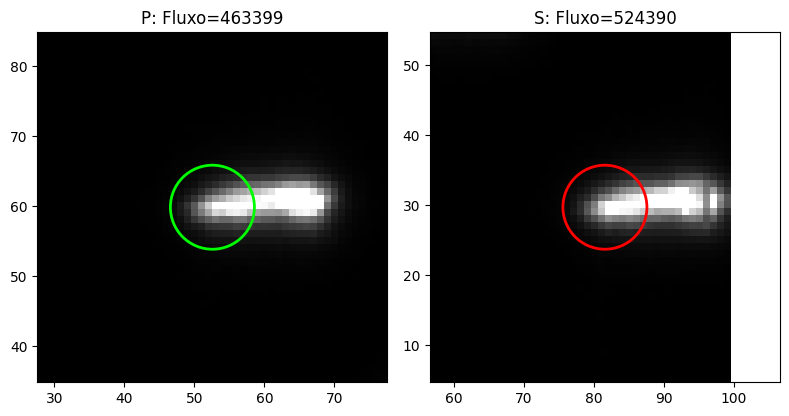

Opções: [ENTER/S] Aceitar | [R] Recalibrar | [M] Mudar Ref | [D] Descartar/Pular Imagem | [C] Desativar Alertas
-> Âncora recalibrada para X=61.7, Y=60.5

⚠️ [ALERTA IMAGEM 207/240] red_nsco_r_007_027.fits


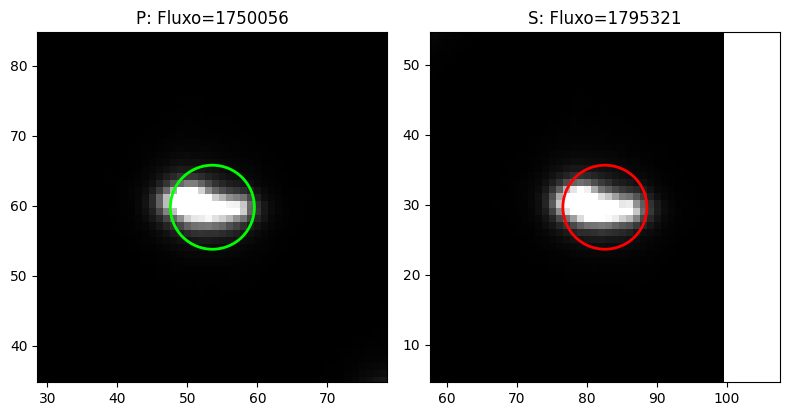

Opções: [ENTER/S] Aceitar | [R] Recalibrar | [M] Mudar Ref | [D] Descartar/Pular Imagem | [C] Desativar Alertas

⚠️ [ALERTA IMAGEM 208/240] red_nsco_r_007_028.fits


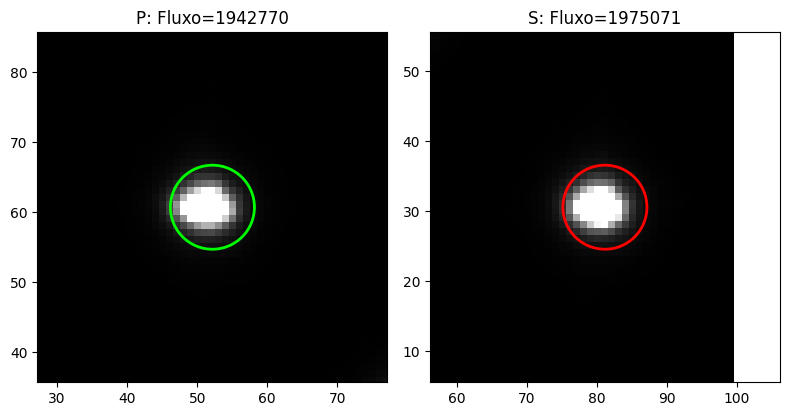

Opções: [ENTER/S] Aceitar | [R] Recalibrar | [M] Mudar Ref | [D] Descartar/Pular Imagem | [C] Desativar Alertas
-> Âncora recalibrada para X=51.2, Y=60.7
[240/240] red_nsco_r_008_030.fits | Pos 11 (247.5°) -> F_Prin=1953572 | F_Sec=2021007
✅ Filtro R finalizado e salvo em /home/likeableng/BeACoN/arquivos_de_reducao/18abr11/reduced/nsco/Obs_1_nsco/fotometria_filtro_r.csv!

PROCESSANDO FILTRO: 'B' (240 imagens)

👉 [FILTRO B] Clique nas estrelas P e S. Veja os atalhos no topo da janela.

[1/240] red_nsco_b_001_001.fits | Pos 0 (0.0°) -> F_Prin=2972831 | F_Sec=2949073
[51/240] red_nsco_b_002_021.fits | Pos 1 (22.5°) -> F_Prin=3000869 | F_Sec=2915295
[101/240] red_nsco_b_004_011.fits | Pos 3 (67.5°) -> F_Prin=2924106 | F_Sec=2950742
[151/240] red_nsco_b_006_001.fits | Pos 9 (202.5°) -> F_Prin=3052148 | F_Sec=2965547
[201/240] red_nsco_b_007_021.fits | Pos 10 (225.0°) -> F_Prin=2916878 | F_Sec=2890038
[240/240] red_nsco_b_008_030.fits | Pos 11 (247.5°) -> F_Prin=3062071 | F_Sec=3106900
✅ Fil

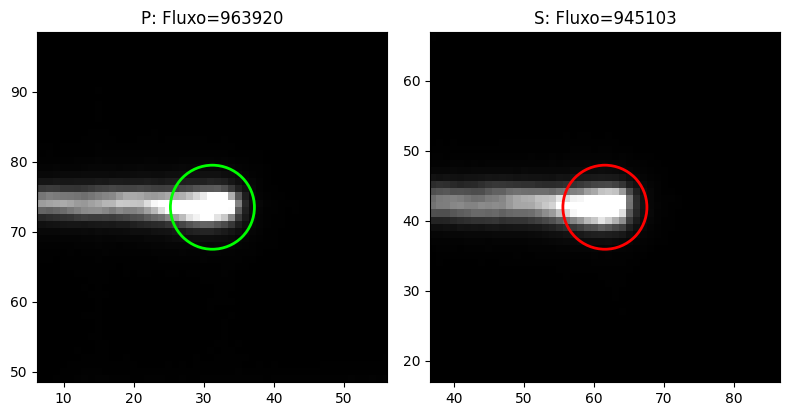

Opções: [ENTER/S] Aceitar | [R] Recalibrar | [M] Mudar Ref | [D] Descartar/Pular Imagem | [C] Desativar Alertas

⚠️ [ALERTA IMAGEM 127/240] red_nsco_b_013_007.fits


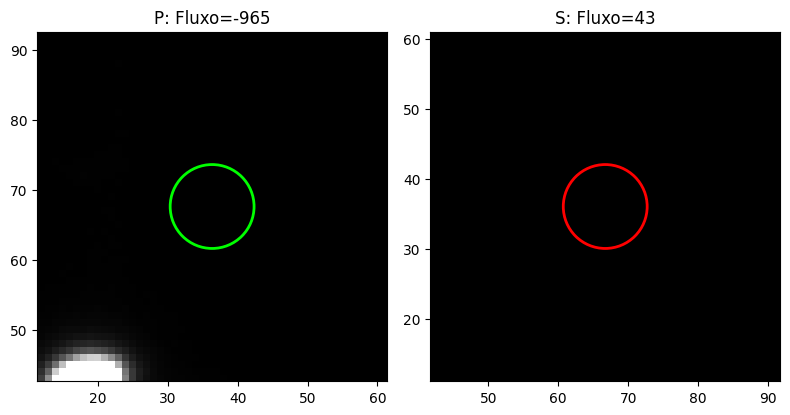

Opções: [ENTER/S] Aceitar | [R] Recalibrar | [M] Mudar Ref | [D] Descartar/Pular Imagem | [C] Desativar Alertas
🚫 Imagem red_nsco_b_013_007.fits foi DESCARTADA e não será salva no CSV!

⚠️ [ALERTA IMAGEM 142/240] red_nsco_b_013_022.fits


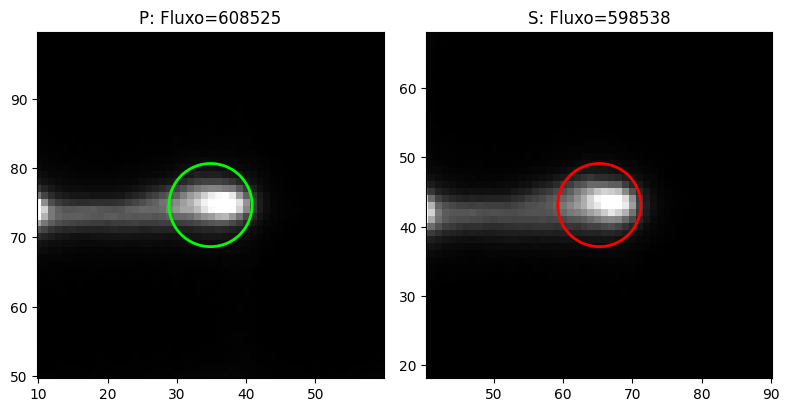

Opções: [ENTER/S] Aceitar | [R] Recalibrar | [M] Mudar Ref | [D] Descartar/Pular Imagem | [C] Desativar Alertas
🚫 Imagem red_nsco_b_013_022.fits foi DESCARTADA e não será salva no CSV!

⚠️ [ALERTA IMAGEM 143/240] red_nsco_b_013_023.fits


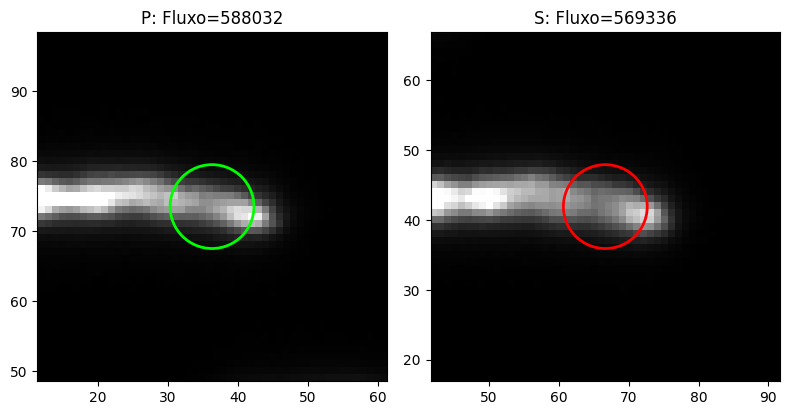

Opções: [ENTER/S] Aceitar | [R] Recalibrar | [M] Mudar Ref | [D] Descartar/Pular Imagem | [C] Desativar Alertas
🚫 Imagem red_nsco_b_013_023.fits foi DESCARTADA e não será salva no CSV!
[151/240] red_nsco_b_014_001.fits | Pos 9 (202.5°) -> F_Prin=3044632 | F_Sec=2962701
[201/240] red_nsco_b_015_021.fits | Pos 10 (225.0°) -> F_Prin=3065733 | F_Sec=3035555
[240/240] red_nsco_b_016_030.fits | Pos 11 (247.5°) -> F_Prin=3052487 | F_Sec=3091009
✅ Filtro B finalizado e salvo em /home/likeableng/BeACoN/arquivos_de_reducao/18abr11/reduced/nsco/Obs_2_nsco/fotometria_filtro_b.csv!

PROCESSANDO FILTRO: 'R' (240 imagens)

👉 [FILTRO R] Clique nas estrelas P e S. Veja os atalhos no topo da janela.

[1/240] red_nsco_r_009_001.fits | Pos 0 (0.0°) -> F_Prin=2069683 | F_Sec=2062466
[51/240] red_nsco_r_010_021.fits | Pos 1 (22.5°) -> F_Prin=1984856 | F_Sec=1953793

⚠️ [ALERTA IMAGEM 65/240] red_nsco_r_011_005.fits


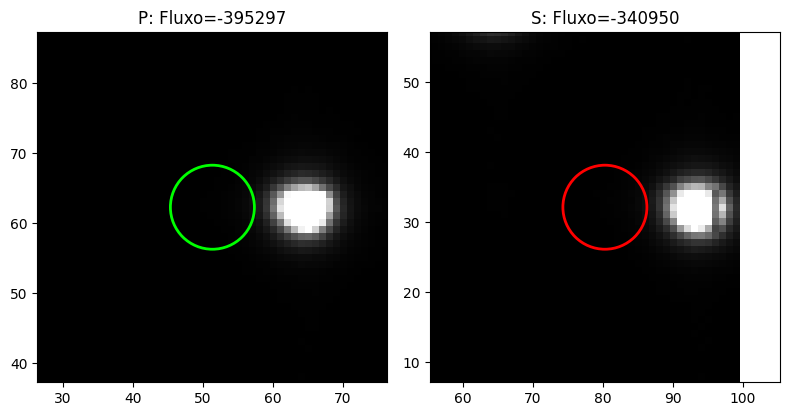

Opções: [ENTER/S] Aceitar | [R] Recalibrar | [M] Mudar Ref | [D] Descartar/Pular Imagem | [C] Desativar Alertas
-> Âncora recalibrada para X=64.5, Y=62.0

⚠️ [ALERTA IMAGEM 68/240] red_nsco_r_011_008.fits


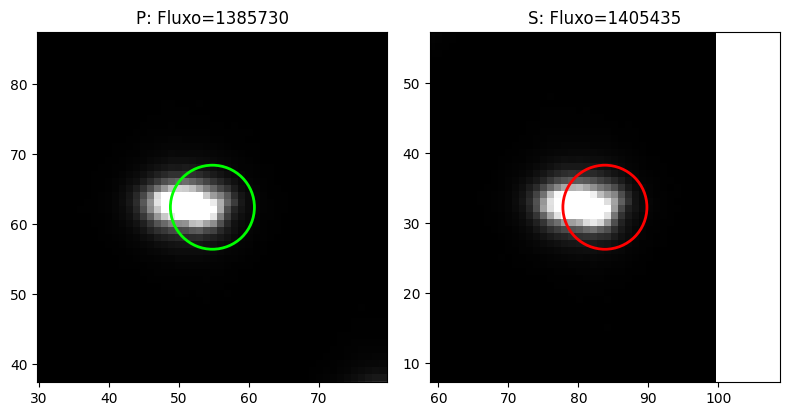

Opções: [ENTER/S] Aceitar | [R] Recalibrar | [M] Mudar Ref | [D] Descartar/Pular Imagem | [C] Desativar Alertas
-> Âncora recalibrada para X=51.1, Y=62.6
[101/240] red_nsco_r_012_011.fits | Pos 3 (67.5°) -> F_Prin=1965820 | F_Sec=2016216
[151/240] red_nsco_r_014_001.fits | Pos 9 (202.5°) -> F_Prin=1979300 | F_Sec=1933095
[201/240] red_nsco_r_015_021.fits | Pos 10 (225.0°) -> F_Prin=1833612 | F_Sec=1848063
[240/240] red_nsco_r_016_030.fits | Pos 11 (247.5°) -> F_Prin=1729144 | F_Sec=1770013
✅ Filtro R finalizado e salvo em /home/likeableng/BeACoN/arquivos_de_reducao/18abr11/reduced/nsco/Obs_2_nsco/fotometria_filtro_r.csv!

PROCESSANDO FILTRO: 'V' (240 imagens)

👉 [FILTRO V] Clique nas estrelas P e S. Veja os atalhos no topo da janela.

[1/240] red_nsco_v_009_001.fits | Pos 0 (0.0°) -> F_Prin=1505370 | F_Sec=1490529
[51/240] red_nsco_v_010_021.fits | Pos 1 (22.5°) -> F_Prin=1905067 | F_Sec=1851163
[101/240] red_nsco_v_012_011.fits | Pos 3 (67.5°) -> F_Prin=1987502 | F_Sec=2017793
[151/24

In [21]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from matplotlib.patches import Circle
from astropy.io import fits
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

%matplotlib inline

# ====================================================================
# HELPER 1: PREPARAÇÃO DA IMAGEM (CONTRASTE LINEAR / LOG)
# ====================================================================
def preparar_imagem_bgr(data_matrix, usar_log=False):
    data_clean = np.nan_to_num(data_matrix, nan=np.nanmedian(data_matrix), posinf=0, neginf=0)
    
    if usar_log:
        data_clean = np.log1p(np.maximum(data_clean - np.min(data_clean), 0))
        
    vmin = np.median(data_clean)
    vmax = np.percentile(data_clean, 99.5)
    if vmax <= vmin:
        vmax = vmin + 1.0
        
    img_norm = np.clip((data_clean - vmin) / (vmax - vmin) * 255, 0, 255).astype(np.uint8)
    img_flip = cv2.flip(img_norm, 0)
    return cv2.cvtColor(img_flip, cv2.COLOR_GRAY2BGR)


# ====================================================================
# HELPER 2: APLICADOR DE ZOOM E MARGEM
# ====================================================================
def aplicar_zoom_e_padding(img_draw, zoom_factor):
    h, w = img_draw.shape[:2]
    
    if abs(zoom_factor - 1.0) < 1e-3:
        return img_draw, 0, 0
    elif zoom_factor > 1.0:
        crop_w, crop_h = int(w / zoom_factor), int(h / zoom_factor)
        x1, y1 = (w - crop_w) // 2, (h - crop_h) // 2
        return img_draw[y1:y1+crop_h, x1:x1+crop_w], x1, y1
    else:
        target_w = int(w / zoom_factor)
        target_h = int(h / zoom_factor)
        pad_w = (target_w - w) // 2
        pad_h = (target_h - h) // 2
        
        img_padded = cv2.copyMakeBorder(
            img_draw, pad_h, pad_h, pad_w, pad_w, 
            cv2.BORDER_CONSTANT, value=(0, 0, 0)
        )
        return img_padded, -pad_w, -pad_h


# ====================================================================
# FUNÇÃO 1: RECALIBRAÇÃO DE ÂNCORA (COM TODOS OS ATALHOS NA BARRA)
# ====================================================================
def recalibrar_ancora_cv2(data_frame, x_atual, y_atual, janela_busca):
    h, w = data_frame.shape
    usar_log = False
    zoom_factor = 1.0
    ponto_novo = []
    
    img_bgr = preparar_imagem_bgr(data_frame, usar_log=usar_log)
    nome_janela_base = "RECALIBRACAO DE ANCORA"

    def mouse_cb(event, x_win, y_win, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN and len(ponto_novo) == 0:
            _, offset_x, offset_y = aplicar_zoom_e_padding(img_bgr, zoom_factor)
            
            x_img = offset_x + x_win
            y_img = offset_y + y_win
            
            x_img_clamped = int(np.clip(x_img, 0, w - 1))
            y_img_clamped = int(np.clip(y_img, 0, h - 1))
            y_fits = (h - 1) - y_img_clamped
            
            ponto_novo.append((x_img_clamped, y_fits))

    cv2.namedWindow(nome_janela_base, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(nome_janela_base, 800, 800)
    cv2.setMouseCallback(nome_janela_base, mouse_cb)

    while True:
        img_draw = img_bgr.copy()
        
        yp_cv, xp_cv = int(round((h - 1) - y_atual)), int(round(x_atual))
        cv2.circle(img_draw, (xp_cv, yp_cv), 2, (0, 0, 255), -1)

        # MONTA O TÍTULO COMPLETO COM TODAS AS OPÇÕES
        if len(ponto_novo) == 0:
            titulo = f"RECALIBRAR ({zoom_factor:.2f}x) -> Clique em P | ATALHOS: [E]Expandir [L]Log [+/Z]ZoomIn [-/X]ZoomOut [0]Reset [ESC]Sair"
        else:
            xn, yn = ponto_novo[0]
            yn_cv, xn_cv = int(round((h - 1) - yn)), int(round(xn))
            cv2.circle(img_draw, (xn_cv, yn_cv), 2, (0, 255, 0), -1)
            cv2.putText(img_draw, "P", (xn_cv + 3, yn_cv - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.25, (0, 255, 0), 1)
            titulo = f"RECALIBRAR ({zoom_factor:.2f}x) -> [ENTER/S]Confirmar [R]Refazer | ATALHOS: [E]Expandir [L]Log [+/Z]ZoomIn [-/X]ZoomOut [ESC]Sair"

        img_view, _, _ = aplicar_zoom_e_padding(img_draw, zoom_factor)

        cv2.setWindowTitle(nome_janela_base, titulo)
        cv2.imshow(nome_janela_base, img_view)
        key = cv2.waitKey(30) & 0xFF

        if key in [13, ord('s'), ord('S')] and len(ponto_novo) > 0:
            break
        elif key in [ord('r'), ord('R')]:
            ponto_novo.clear()
        elif key in [ord('e'), ord('E')]:
            zoom_factor = 0.5 if zoom_factor == 1.0 else 1.0
        elif key in [ord('+'), ord('='), ord('z'), ord('Z')]:
            zoom_factor = min(zoom_factor * 1.3, 8.0)
        elif key in [ord('-'), ord('_'), ord('x'), ord('X')]:
            zoom_factor = max(zoom_factor / 1.3, 0.25)
        elif key == ord('0'):
            zoom_factor = 1.0
        elif key in [ord('l'), ord('L')]:
            usar_log = not usar_log
            img_bgr = preparar_imagem_bgr(data_frame, usar_log=usar_log)
        elif key in [27, ord('q'), ord('Q')]:
            break

    cv2.destroyAllWindows()
    for _ in range(5): cv2.waitKey(1)

    if len(ponto_novo) > 0:
        xn, yn = ponto_novo[0]
        return rastrear_centroide_ancorado(data_frame, xn, yn, janela=janela_busca)
    
    return x_atual, y_atual


# ====================================================================
# FUNÇÃO 2: SELEÇÃO DO PAR (COM TODOS OS ATALHOS NA BARRA)
# ====================================================================
def selecionar_e_confirmar_par_cv2(data_ref, filtro_nome, raio_abertura, r_in_sky, r_out_sky, janela_busca):
    h, w = data_ref.shape
    usar_log = False
    zoom_factor = 1.0
    
    img_bgr = preparar_imagem_bgr(data_ref, usar_log=usar_log)
    
    pontos = []
    x_p_ref, y_p_ref = None, None
    x_s_ref, y_s_ref = None, None
    
    nome_janela = f"SELECAO DE PAR - FILTRO {filtro_nome.upper()}"

    def mouse_callback(event, x_win, y_win, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN and len(pontos) < 2:
            _, offset_x, offset_y = aplicar_zoom_e_padding(img_bgr, zoom_factor)
            
            x_img = offset_x + x_win
            y_img = offset_y + y_win
            
            x_img_clamped = int(np.clip(x_img, 0, w - 1))
            y_img_clamped = int(np.clip(y_img, 0, h - 1))
            y_fits = (h - 1) - y_img_clamped
            
            pontos.append((x_img_clamped, y_fits))

    cv2.namedWindow(nome_janela, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(nome_janela, 800, 800)
    cv2.setMouseCallback(nome_janela, mouse_callback)

    print(f"\n👉 [FILTRO {filtro_nome.upper()}] Clique nas estrelas P e S. Veja os atalhos no topo da janela.\n")

    confirmado = False
    while True:
        img_draw = img_bgr.copy()
        
        # MONTA O TÍTULO DETALHADO DA BARRA SUPERIOR
        if len(pontos) == 0:
            titulo = f"FILTRO {filtro_nome.upper()} ({zoom_factor:.2f}x) -> [1/2] Clique em P | ATALHOS: [E]Expandir [L]Log [+/Z]ZoomIn [-/X]ZoomOut [0]Reset [ESC]Sair"
        elif len(pontos) == 1:
            titulo = f"FILTRO {filtro_nome.upper()} ({zoom_factor:.2f}x) -> [2/2] Clique em S | ATALHOS: [E]Expandir [L]Log [+/Z]ZoomIn [-/X]ZoomOut [0]Reset [ESC]Sair"
            xp, yp_cv = int(pontos[0][0]), int((h - 1) - pontos[0][1])
            cv2.circle(img_draw, (xp, yp_cv), 2, (0, 255, 0), -1)
        elif len(pontos) == 2:
            x_p_ref, y_p_ref = rastrear_centroide_ancorado(data_ref, pontos[0][0], pontos[0][1], janela=janela_busca)
            x_s_ref, y_s_ref = rastrear_centroide_ancorado(data_ref, pontos[1][0], pontos[1][1], janela=janela_busca)
            
            yp_cv, xp_cv = int(round((h - 1) - y_p_ref)), int(round(x_p_ref))
            ys_cv, xs_cv = int(round((h - 1) - y_s_ref)), int(round(x_s_ref))
            
            cv2.circle(img_draw, (xp_cv, yp_cv), int(raio_abertura), (0, 255, 0), 1)
            cv2.circle(img_draw, (xp_cv, yp_cv), int(r_in_sky), (0, 255, 255), 1)
            cv2.circle(img_draw, (xp_cv, yp_cv), int(r_out_sky), (0, 255, 255), 1)
            cv2.putText(img_draw, "P", (xp_cv + 4, yp_cv - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.25, (0, 255, 0), 1)
            
            cv2.circle(img_draw, (xs_cv, ys_cv), int(raio_abertura), (0, 0, 255), 1)
            cv2.circle(img_draw, (xs_cv, ys_cv), int(r_in_sky), (0, 255, 255), 1)
            cv2.circle(img_draw, (xs_cv, ys_cv), int(r_out_sky), (0, 255, 255), 1)
            cv2.putText(img_draw, "S", (xs_cv + 4, ys_cv - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.25, (0, 0, 255), 1)
            
            titulo = f"FILTRO {filtro_nome.upper()} ({zoom_factor:.2f}x) -> [ENTER/S]Confirmar [R]Refazer | ATALHOS: [E]Expandir [L]Log [+/Z]ZoomIn [-/X]ZoomOut [ESC]Pular"

        img_view, _, _ = aplicar_zoom_e_padding(img_draw, zoom_factor)

        cv2.setWindowTitle(nome_janela, titulo)
        cv2.imshow(nome_janela, img_view)
        
        key = cv2.waitKey(30) & 0xFF
        if key in [13, ord('s'), ord('S')] and len(pontos) == 2:
            confirmado = True
            break
        elif key in [ord('r'), ord('R')]:
            pontos.clear()
            print("   🔄 Cliques limpos. Selecione P e S novamente.")
        elif key in [ord('e'), ord('E')]:
            zoom_factor = 0.5 if zoom_factor == 1.0 else 1.0
        elif key in [ord('+'), ord('='), ord('z'), ord('Z')]:
            zoom_factor = min(zoom_factor * 1.3, 8.0)
        elif key in [ord('-'), ord('_'), ord('x'), ord('X')]:
            zoom_factor = max(zoom_factor / 1.3, 0.25)
        elif key == ord('0'):
            zoom_factor = 1.0
        elif key in [ord('l'), ord('L')]:
            usar_log = not usar_log
            img_bgr = preparar_imagem_bgr(data_ref, usar_log=usar_log)
        elif key in [27, ord('q'), ord('Q')]:
            confirmado = False
            break

    cv2.destroyAllWindows()
    for _ in range(5): cv2.waitKey(1)
        
    if confirmado:
        return x_p_ref, y_p_ref, x_s_ref, y_s_ref
    else:
        return None, None, None, None


# ====================================================================
# LOOP PRINCIPAL DE BUSCA E EXTRAÇÃO FOTOMÉTRICA
# ====================================================================
for i in range(vezes_repetido):

    pasta_reduced_estrela_i = f"{pasta_reduced_estrela}/Obs_{i+1}_{NOME_ESTRELA}"
        
    todos_arquivos = glob.glob(os.path.join(pasta_reduced_estrela_i, 'red_*.fits'))

    if not todos_arquivos:
        print(f"[AVISO] Nenhum arquivo 'red_*.fits' encontrado em {pasta_reduced_estrela_i}.")
        continue

    arquivos_por_filtro = defaultdict(list)
    for arq in todos_arquivos:
        nome = os.path.basename(arq)
        partes = nome.split('_')
        if len(partes) >= 5:
            filtro = partes[2]
            arquivos_por_filtro[filtro].append(arq)

    print("=== PIPELINE BLINDADO DE FOTOMETRIA BEACON ===")
    print(f"Filtros identificados na Obs {i+1}: {list(arquivos_por_filtro.keys())}\n")

    for filtro, arquivos in arquivos_por_filtro.items():
        arquivos = sorted(arquivos)
        total_arq = len(arquivos)
        
        print(f"\n{'='*60}")
        print(f"PROCESSANDO FILTRO: '{filtro.upper()}' ({total_arq} imagens)")
        print(f"{'='*60}")
        
        imagem_referencia = arquivos[0]
        data_ref = fits.getdata(imagem_referencia)
        data_ref = np.squeeze(data_ref)
        data_ref = np.nan_to_num(data_ref, nan=np.nanmedian(data_ref), posinf=0, neginf=0)

        # 1. Seleção e Confirmação Direta no OpenCV
        x_prin_ref, y_prin_ref, x_sec_ref, y_sec_ref = selecionar_e_confirmar_par_cv2(
            data_ref, filtro, raio_abertura, r_in_sky, r_out_sky, janela_busca
        )

        if x_prin_ref is None:
            print(f"⚠️ [AVISO] Seleção ignorada/cancelada. Pulando filtro {filtro.upper()}...")
            continue

        dx_rigido = x_sec_ref - x_prin_ref
        dy_rigido = y_sec_ref - y_prin_ref

        # 2. Extração Fotométrica nos Arquivos
        arquivo_saida = os.path.join(pasta_reduced_estrela_i, f'fotometria_filtro_{filtro}.csv')

        with open(arquivo_saida, 'w') as f_out:
            f_out.write("Arquivo,Posicao,Angulo,X_Prin,Y_Prin,Fluxo_Prin,Pico_Prin,X_Sec,Y_Sec,Fluxo_Sec,Pico_Sec,Status\n")
            
            fluxo_p_ref = None
            fluxo_s_ref = None
            ignorar_alertas = False

            for i_arq, arq in enumerate(arquivos):
                nome = os.path.basename(arq)
                try:
                    hdr = fits.getheader(arq)
                    lamina_raw = str(hdr.get('LAMINA', 'L0')).strip().upper()
                    angulo_psi = mapa_lamina_graus.get(lamina_raw, 0.0)
                    posicao_int = int(angulo_psi / 22.5)
                except Exception:
                    posicao_int, angulo_psi = 0, 0.0
                
                dados = fits.getdata(arq)
                dados = np.squeeze(dados)
                dados = np.nan_to_num(dados, nan=np.nanmedian(dados), posinf=0, neginf=0)
                
                x_prin, y_prin = rastrear_centroide_ancorado(dados, x_prin_ref, y_prin_ref, janela=janela_busca)
                x_sec = x_prin + dx_rigido
                y_sec = y_prin + dy_rigido
                
                h, w = dados.shape
                xi_p, yi_p = int(round(x_prin)), int(round(y_prin))
                pico_p = np.max(dados[max(0, yi_p-3):min(h, yi_p+4), max(0, xi_p-3):min(w, xi_p+4)])

                xi_s, yi_s = int(round(x_sec)), int(round(y_sec))
                pico_s = np.max(dados[max(0, yi_s-3):min(h, yi_s+4), max(0, xi_s-3):min(w, xi_s+4)])
                
                aper_p = CircularAperture((x_prin, y_prin), r=raio_abertura)
                ann_p = CircularAnnulus((x_prin, y_prin), r_in=r_in_sky, r_out=r_out_sky)
                phot_p = aperture_photometry(dados, [aper_p, ann_p])
                
                aper_s = CircularAperture((x_sec, y_sec), r=raio_abertura)
                ann_s = CircularAnnulus((x_sec, y_sec), r_in=r_in_sky, r_out=r_out_sky)
                phot_s = aperture_photometry(dados, [aper_s, ann_s])
                
                bkg_p_pixel = phot_p['aperture_sum_1'][0] / area_ann
                fluxo_p = phot_p['aperture_sum_0'][0] - (bkg_p_pixel * area_aper)
                
                bkg_s_pixel = phot_s['aperture_sum_1'][0] / area_ann
                fluxo_s = phot_s['aperture_sum_0'][0] - (bkg_s_pixel * area_aper)
                
                if i_arq == 0:
                    fluxo_p_ref, fluxo_s_ref = max(fluxo_p, 100.0), max(fluxo_s, 100.0)

                # Alertas Inteligentes
                desvio_posicao = np.sqrt((x_prin - x_prin_ref)**2 + (y_prin - y_prin_ref)**2)
                queda_critica = (fluxo_p < 0.20 * fluxo_p_ref) or (fluxo_s < 0.20 * fluxo_s_ref)
                deslocado_critico = desvio_posicao > 8.0

                status_imagem = "VALIDA"
                pular_escrita = False

                if (queda_critica or deslocado_critico) and not ignorar_alertas:
                    print(f"\n⚠️ [ALERTA IMAGEM {i_arq+1}/{total_arq}] {nome}")
                    
                    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
                    vmin, vmax = np.median(dados), np.percentile(dados, 99.5)
                    
                    ax1.imshow(dados, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
                    ax1.add_patch(Circle((x_prin, y_prin), raio_abertura, color='lime', fill=False, lw=2))
                    ax1.set_xlim(x_prin - 25, x_prin + 25)
                    ax1.set_ylim(y_prin - 25, y_prin + 25)
                    ax1.set_title(f"P: Fluxo={fluxo_p:.0f}")
                    
                    ax2.imshow(dados, cmap="gray", origin="lower", vmin=vmin, vmax=vmax)
                    ax2.add_patch(Circle((x_sec, y_sec), raio_abertura, color='red', fill=False, lw=2))
                    ax2.set_xlim(x_sec - 25, x_sec + 25)
                    ax2.set_ylim(y_sec - 25, y_sec + 25)
                    ax2.set_title(f"S: Fluxo={fluxo_s:.0f}")
                    
                    plt.tight_layout()
                    plt.show()

                    print("Opções: [ENTER/S] Aceitar | [R] Recalibrar | [M] Mudar Ref | [D] Descartar/Pular Imagem | [C] Desativar Alertas")
                    resp = input("Escolha (ENTER/S/R/M/D/C): ").upper().strip()
                    if resp == 'R':
                        x_prin_ref, y_prin_ref = recalibrar_ancora_cv2(dados, x_prin, y_prin, janela_busca)
                        x_prin, y_prin = x_prin_ref, y_prin_ref
                        x_sec, y_sec = x_prin + dx_rigido, y_prin + dy_rigido
                        print(f"-> Âncora recalibrada para X={x_prin_ref:.1f}, Y={y_prin_ref:.1f}")
                    elif resp == 'M':
                        fluxo_p_ref, fluxo_s_ref = max(fluxo_p, 100.0), max(fluxo_s, 100.0)
                    elif resp == 'D':
                        pular_escrita = True
                        print(f"🚫 Imagem {nome} foi DESCARTADA e não será salva no CSV!")
                    elif resp == 'C':
                        ignorar_alertas = True

                if pular_escrita:
                    continue

                if i_arq % 50 == 0 or i_arq == total_arq - 1:
                    print(f"[{i_arq+1}/{total_arq}] {nome} | Pos {posicao_int} ({angulo_psi}°) -> F_Prin={fluxo_p:.0f} | F_Sec={fluxo_s:.0f}")
                
                f_out.write(f"{nome},{posicao_int},{angulo_psi:.1f},{x_prin},{y_prin},{fluxo_p:.3f},{pico_p:.1f},{x_sec},{y_sec},{fluxo_s:.3f},{pico_s:.1f},{status_imagem}\n") 
                              
        print(f"✅ Filtro {filtro.upper()} finalizado e salvo em {arquivo_saida}!")

print("\n=== EXTRAÇÃO FOTOMÉTRICA CONCLUÍDA COM SUCESSO! ===")

# **Dados Finais 1**

2026-10-19 04:39:15,453 astropop - INFO - Errors will not be considered in the fit.  [__init__]


2026-10-19 04:39:15,468 astropop - INFO - Errors will not be considered in the fit.  [__init__]


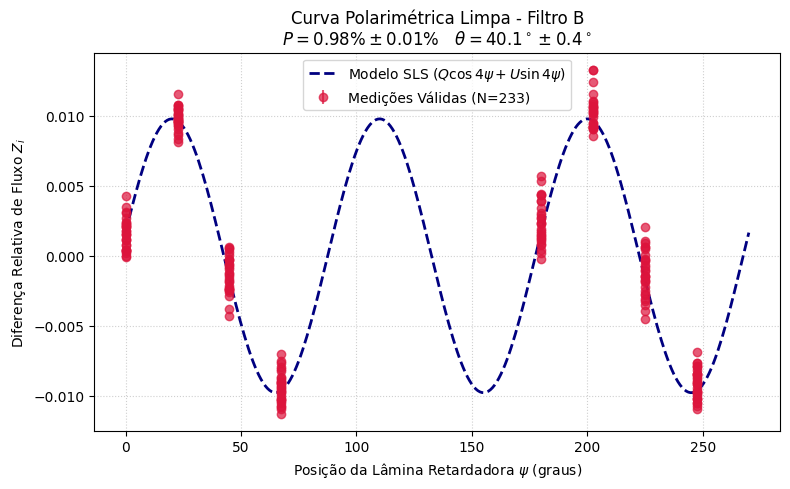

TypeError: '>' not supported between instances of 'str' and 'int'

In [25]:
# Ajustes para o final
for i in range(vezes_repetido):
    
    pasta_reduced_estrela_i = f"{pasta_reduced_estrela}/Obs_{i+1}_{NOME_ESTRELA}"
    arquivos_csv = sorted(glob.glob(os.path.join(pasta_reduced_estrela_i, 'fotometria_filtro_*.csv')))

    if not arquivos_csv:
        raise FileNotFoundError(f"Nenhum arquivo CSV de fotometria foi encontrado em {pasta_reduced_estrela_i}.")

    # Solver de Mínimos Quadrados do astropop para lâmina de meia-onda
    pol_solver = SLSDualBeamPolarimetry('halfwave', compute_k=True)

    resultados_finais = []

    # Resumo final em tabela no terminal
    for csv_file in arquivos_csv:
        filtro = os.path.basename(csv_file).split('_')[-1].replace('.csv', '').upper()
        df = pd.read_csv(csv_file)
        
        # 1. Filtra quadros com contaminação severa/fluxos inválidos
        df_valido = df[(df['Fluxo_Prin'] > 100) & (df['Fluxo_Sec'] > 100)].copy()
        
        # 2. Descarte primário de dispersões grotescas (|Zi| >= 0.20)
        df_valido['Zi_raw'] = (df_valido['Fluxo_Sec'] - df_valido['Fluxo_Prin']) / (df_valido['Fluxo_Sec'] + df_valido['Fluxo_Prin'])
        df_limpo = df_valido[np.abs(df_valido['Zi_raw']) < 0.20].copy()
        
        if len(df_limpo) == 0:
            print(f"[{filtro}] Nenhum dado válido restou após filtros primários.")
            continue

        psi = df_limpo['Angulo'].values
        fo = df_limpo['Fluxo_Prin'].values
        fe = df_limpo['Fluxo_Sec'].values
        
        # 3. Ajuste preliminar no astropop
        res_preliminar = pol_solver.compute(psi, fo, fe)
        
        # 4. Rejeição refinada por 3-Sigma nos resíduos do modelo
        residuos = res_preliminar.zi.nominal - res_preliminar.model(psi * u.deg).nominal
        mascara_boa = ~sigma_clip(residuos, sigma=3.0).mask
        
        # 5. Ajuste Final de Mínimos Quadrados
        resultado_final = pol_solver.compute(psi[mascara_boa], fo[mascara_boa], fe[mascara_boa])
        
        n_total = len(df)
        n_usados = np.sum(mascara_boa)
        
        p_pct = resultado_final.p.nominal * 100
        p_err = resultado_final.p.std_dev * 100
        theta_deg = resultado_final.theta.nominal
        theta_err = resultado_final.theta.std_dev
        
        resultados_finais.append({
            'Filtro': filtro,
            'N_Usados': f"{n_usados}/{n_total}",
            'P (%)': f"{p_pct:.3f} ± {p_err:.3f}",
            'Theta (°)': f"{theta_deg:.2f} ± {theta_err:.2f}",
            'k': f"{resultado_final.k:.4f}",
            'RMS': f"{resultado_final.rms:.6f}"
        })
        
        # 6. Plotagem da Curva de Modulação
        plt.figure(figsize=(8, 5))
        
        plt.errorbar(resultado_final.psi.nominal, resultado_final.zi.nominal, 
                    yerr=resultado_final.zi.std_dev, fmt='o', color='crimson', 
                    alpha=0.7, label=f'Medições Válidas (N={n_usados})')
        
        eixo_psi = np.linspace(0, 270, 300)
        modelo_zi = resultado_final.model(eixo_psi * u.deg).nominal
        plt.plot(eixo_psi, modelo_zi, '--', color='navy', lw=2, label='Modelo SLS ($Q\cos 4\psi + U\sin 4\psi$)')
        
        plt.title(f"Curva Polarimétrica Limpa - Filtro {filtro}\n$P = {p_pct:.2f}\% \pm {p_err:.2f}\% \quad \\theta = {theta_deg:.1f}^\circ \pm {theta_err:.1f}^\circ$")
        plt.xlabel(r"Posição da Lâmina Retardadora $\psi$ (graus)")
        plt.ylabel(r"Diferença Relativa de Fluxo $Z_i$")
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend(loc='best')
        plt.tight_layout()
        
        # --- NOVIDADE: Salvar a imagem do gráfico ---
        nome_grafico = f"curva_polarimetrica_filtro_{filtro}.png"
        caminho_grafico = os.path.join(pasta_reduced_estrela_i, nome_grafico)
        plt.savefig(caminho_grafico, dpi=300, bbox_inches='tight')
        
        plt.show()

    # --- NOVIDADE: Salvar o resumo em um arquivo .out ---
    if resultados_finais:
        print("\n" + "="*70)
        print(f"  RESUMO DA POLARIMETRIA FINAL - {NOME_ESTRELA.upper()} (OBS {i+1})")
        print("="*70)
        
        df_resumo = pd.DataFrame(resultados_finais)
        tabela_texto = df_resumo.to_string(index=False)
        print(tabela_texto)

        caminho_out = os.path.join(pasta_reduced_estrela_i, f"resultados_polarimetria_obs{i+1}_{NOME_ESTRELA}.out")
        
        with open(caminho_out, 'w', encoding='utf-8') as f_out:
            f_out.write("="*70 + "\n")
            f_out.write(f"  RESUMO DA POLARIMETRIA FINAL - {NOME_ESTRELA.upper()} (OBS {i+1})\n")
            f_out.write("="*70 + "\n\n")
            f_out.write(tabela_texto + "\n")
            
        print(f"\n✅ Resultados numéricos salvos em: {caminho_out}\n")